# Genetic Algorithm for Engineering Signal Parameter Estimation

## Objective

Implement a real-coded genetic algorithm to estimate
the unknown parameters of a damped oscillatory signal
from noisy measurements.

The signal model is:
$$
y(t) = A e^{-\alpha t} sin(2 \pi ft)
$$
The unknown parameters are:

- A: Initial amplitude
- alpha: Damping coefficient
- f: Frequency

The algorithm will minimise the mean squared error
between the observed signal and the predicted signal.

## 1. Importing the libraries

We use NumPy for numerical computation and random-number
generation, Matplotlib for visualisation, and Pandas
for presenting the parameter-estimation results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
rng = np.random.default_rng(42)

## 2. Signal model

Define the mathematical model of the damped oscillatory
signal.

The model depends on three parameters:

- A: Initial amplitude
- alpha: Damping coefficient
- f: Frequency

In [4]:
def damped_signal(t, A, alpha, f):

    signal = (
        A
        * np.exp(-alpha * t)
        * np.sin(2 * np.pi * f * t)
    )

    return signal

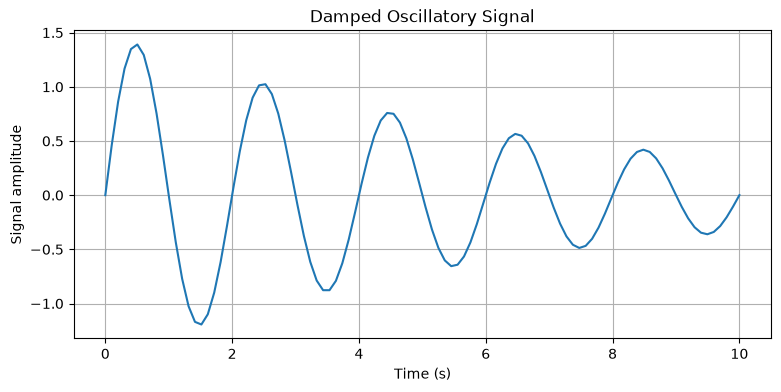

In [6]:
test_time = np.linspace(0, 10, 100)

test_signal = damped_signal(
    test_time,
    A=1.5,
    alpha=0.15,
    f=0.5
)

plt.figure(figsize=(9, 4))

plt.plot(test_time, test_signal)

plt.xlabel("Time (s)")
plt.ylabel("Signal amplitude")
plt.title("Damped Oscillatory Signal")

plt.grid(True)
plt.show()

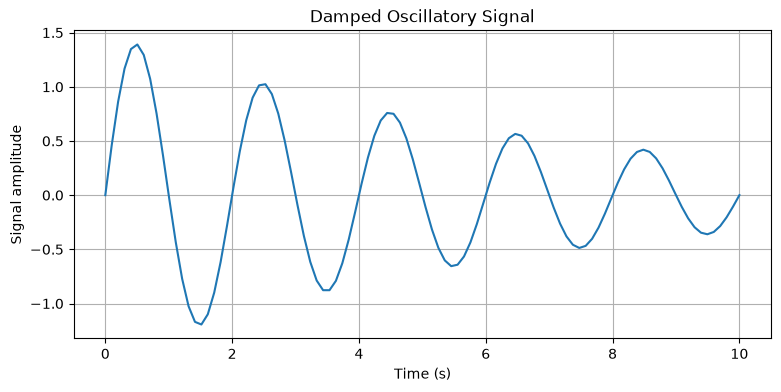

In [7]:
test_time = np.linspace(0, 10, 100)

test_signal = damped_signal(
    test_time,
    A=1.5,
    alpha=0.15,
    f=0.5
)

plt.figure(figsize=(9, 4))

plt.plot(test_time, test_signal)

plt.xlabel("Time (s)")
plt.ylabel("Signal amplitude")
plt.title("Damped Oscillatory Signal")

plt.grid(True)
plt.show()

## 3. Generating observed measurements

For this experiment, we simulate measurements from
a system with known parameters.

We define the true signal and introduce Gaussian
measurement noise.

The genetic algorithm will receive only the noisy
measurements, not the true parameters.

In [8]:
# True parameters used to generate the signal
true_parameters = np.array([1.5, 0.15, 0.5])

# Generate measurement time points
time = np.linspace(0, 20, 400)

# Measurement noise level
noise_std = 0.05

# Generate the ideal signal
true_signal = damped_signal(
    time,
    *true_parameters
)

# Add random measurement noise
observed_signal = (
    true_signal
    + rng.normal(
        loc=0.0,
        scale=noise_std,
        size=len(time)
    )
)

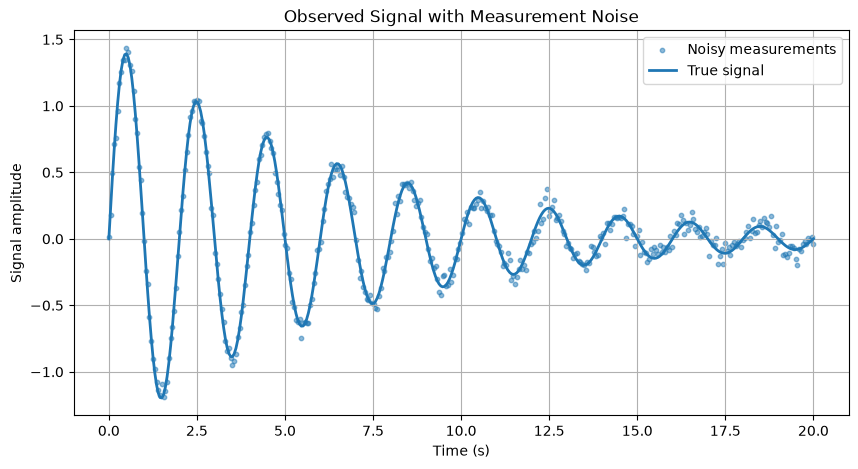

In [15]:
plt.figure(figsize=(10, 5))

plt.scatter(
    time,
    observed_signal,
    s=10,
    alpha=0.5,
    label="Noisy measurements"
)

plt.plot(
    time,
    true_signal,
    label="True signal",
    linewidth=2
)

plt.xlabel("Time (s)")
plt.ylabel("Signal amplitude")

plt.title("Observed Signal with Measurement Noise")

plt.legend()
plt.grid(True)

plt.show()

## 4. Objective-function definition

The objective function measures how closely a candidate
parameter combination reproduces the observed signal.

For each candidate $[A, \alpha, f]$, we:

1. Predict the signal using the mathematical model.
2. Calculate the difference between the predicted
   and observed measurements.
3. Square the differences.
4. Calculate their average.

This gives the mean squared error (MSE).

Our objective is to minimise the MSE.

In [16]:
def objective_function(
    candidate_parameters,
    time,
    observed_signal
):

    A, alpha, f = candidate_parameters

    predicted_signal = damped_signal(
        time,
        A,
        alpha,
        f
    )

    errors = observed_signal - predicted_signal

    mse = np.mean(errors ** 2)

    return mse

In [17]:
test_candidate = np.array([1.2, 0.20, 0.45])

test_mse = objective_function(
    test_candidate,
    time,
    observed_signal
)

print("Test candidate:", test_candidate)
print("Mean squared error:", test_mse)

Test candidate: [1.2  0.2  0.45]
Mean squared error: 0.13634775307243763


## 5. Search boundaries and algorithm parameters

Each individual contains three parameters.

We define lower and upper boundaries for each parameter
to restrict the algorithm's search space.

We also define the settings controlling the genetic
algorithm's evolutionary operations.

In [18]:
# Parameter boundaries
lower_bounds = np.array([
    0.5,    # Minimum amplitude
    0.01,   # Minimum damping coefficient
    0.20    # Minimum frequency
])

upper_bounds = np.array([
    2.5,    # Maximum amplitude
    0.50,   # Maximum damping coefficient
    0.80    # Maximum frequency
])


# Genetic algorithm settings
population_size = 40
number_generations = 100

# Selection settings
tournament_size = 3

# Crossover settings
crossover_probability = 0.9

# Mutation settings
mutation_probability = 0.15

mutation_scales = np.array([
    0.10,   # Amplitude mutation scale
    0.025,  # Damping mutation scale
    0.025   # Frequency mutation scale
])

# Elitism
elitism_count = 2

## 6. Population initialisation

Each individual is represented by three real-valued
parameters:
$$
[A, \alpha, f]
$$
The initial population is generated randomly within
the specified parameter boundaries.

In [19]:
population = rng.uniform(
    low=lower_bounds,
    high=upper_bounds,
    size=(population_size, 3)
)

print("Population shape:", population.shape)

print("\nFirst five individuals:")
print(population[:5])

Population shape: (40, 3)

First five individuals:
[[0.78604375 0.39061629 0.31892254]
 [2.32127645 0.33157183 0.22169763]
 [0.51085967 0.03531238 0.56355511]
 [2.10296362 0.12689088 0.70964531]
 [0.61446388 0.40247229 0.75667726]]


## 7. Population evaluation

Evaluate each individual using the objective function.

Candidates with smaller MSE values represent better
fits to the observed measurements.

In [21]:
objective_values = np.array([
    objective_function(
        individual,
        time,
        observed_signal
    )
    for individual in population
])

In [22]:
for i in range(5):

    print(
        f"Individual {i+1}: "
        f"Parameters = {population[i]}, "
        f"MSE = {objective_values[i]:.6f}"
    )

Individual 1: Parameters = [0.78604375 0.39061629 0.31892254], MSE = 0.187412
Individual 2: Parameters = [2.32127645 0.33157183 0.22169763], MSE = 0.356439
Individual 3: Parameters = [0.51085967 0.03531238 0.56355511], MSE = 0.217835
Individual 4: Parameters = [2.10296362 0.12689088 0.70964531], MSE = 0.596588
Individual 5: Parameters = [0.61446388 0.40247229 0.75667726], MSE = 0.190696


In [23]:
best_index = np.argmin(objective_values)

best_candidate = population[best_index]

best_mse = objective_values[best_index]

print("\nBest initial candidate:", best_candidate)
print("Best initial MSE:", best_mse)


Best initial candidate: [1.75202496 0.18672209 0.50764355]
Best initial MSE: 0.012221515570352337


## 8. Tournament selection

Randomly select a specified number of individuals
from the population.

The individual with the smallest objective value
wins the tournament and is selected as a parent.

In [25]:
def tournament_selection(
    population,
    objective_values,
    tournament_size
):

    competitor_indices = rng.choice(
        len(population),
        size=tournament_size,
        replace=False
    )

    winner_index = competitor_indices[
        np.argmin(
            objective_values[competitor_indices]
        )
    ]

    return population[winner_index].copy()

In [30]:
parent = tournament_selection(
    population,
    objective_values,
    tournament_size
)

print("Selected parent:", parent)

print(
    "Parent MSE:",
    objective_function(parent, time, observed_signal)
)

Selected parent: [0.86706646 0.49021332 0.47513639]
Parent MSE: 0.11164876038180947


## 9. Arithmetic crossover

Crossover combines the parameter values of two parents
to produce an offspring.

We use real-valued arithmetic crossover.

A separate random blending coefficient is generated
for each parameter.

In [32]:
def arithmetic_crossover(parent1, parent2):

    alpha = rng.random(size=parent1.shape)

    child = (
        alpha * parent1
        + (1 - alpha) * parent2
    )

    return child

In [35]:
parent1 = np.array([1.2, 0.20, 0.45])

parent2 = np.array([1.8, 0.10, 0.60])

child = arithmetic_crossover(parent1, parent2)

print("Parent 1:", parent1)
print("Parent 2:", parent2)
print("Offspring:", child)

Parent 1: [1.2  0.2  0.45]
Parent 2: [1.8 0.1 0.6]
Offspring: [1.66028863 0.12920593 0.52647037]


## 10. Gaussian mutation

Mutation introduces random changes into an offspring.

Each parameter has an independent probability of mutation.

The size of the change is controlled by the corresponding
mutation scale.

We also enforce the parameter boundaries after mutation.

In [36]:
def mutate(
    child,
    mutation_probability,
    mutation_scales
):

    mutated_child = child.copy()

    # Determine which parameters will mutate
    mutation_mask = (
        rng.random(size=mutated_child.shape)
        < mutation_probability
    )

    # Generate random changes
    mutation_values = rng.normal(
        loc=0.0,
        scale=mutation_scales,
        size=mutated_child.shape
    )

    # Apply changes only to selected parameters
    mutated_child += mutation_mask * mutation_values

    # Enforce parameter boundaries
    mutated_child = np.clip(
        mutated_child,
        lower_bounds,
        upper_bounds
    )

    return mutated_child

In [51]:
test_child = np.array([1.4, 0.18, 0.48])

mutated_child = mutate(
    test_child,
    mutation_probability,
    mutation_scales
)

print("Before mutation:", test_child)
print("After mutation:", mutated_child)

Before mutation: [1.4  0.18 0.48]
After mutation: [1.4        0.18       0.49177841]


## 11. Complete genetic algorithm

The algorithm performs the following operations:

1. Evaluate the population.
2. Identify the best candidates.
3. Record the population's performance.
4. Preserve elite candidates.
5. Select parents through tournament selection.
6. Apply crossover.
7. Apply mutation.
8. Construct the next generation.
9. Repeat until the maximum number of generations
   is reached.